# 02 — Data Quality

Checks the integrity of the telemetry and investigates the unusual value ranges listed in
`docs/dataset-card.md`. **Nothing is dropped or modified here.** Each issue ends with a decision for
Phase 2 preprocessing, and per-window flags are written to `artifacts/reports/data_quality_flags.csv`.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from flightops.config import load_data_config, project_root
from flightops.data.processed import load_processed
from flightops.data.quality import parse_flight_record
from flightops.data.schema import FEATURES, FEATURE_NAMES, IDX, LABELS

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
FIG_DIR = project_root() / "artifacts" / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CLASS_COLORS = {0: "#4c72b0", 1: "#dd8452", 2: "#55a868", 3: "#c44e52"}

cfg = load_data_config()
X, y = load_processed()          # X is memory-mapped float32: (windows, seconds, variables)
meta = pd.read_csv(cfg.metadata_path, dtype={"flight_record": str})
meta = meta.join(parse_flight_record(meta["flight_record"]))
assert len(meta) == len(y) and (meta["label"].to_numpy() == y).all()
print("X:", X.shape, X.dtype, "| y:", y.shape, y.dtype)

from flightops.data.quality import (FLAP_JUMP_COUNTS, PRESSURE_INVALID_MBAR, VERT_ACCEL_RANGE_G,
                                    duplicate_mask, window_hashes, window_quality_flags, wrap_degrees)

def col(name):
    return np.asarray(X[:, :, IDX[name]])

X: (99837, 160, 20) float32 | y: (99837,) int8


## 1. Integrity

In [2]:
nonfinite = sum(int((~np.isfinite(X[s:s + 8192])).sum()) for s in range(0, len(X), 8192))
print("non-finite values:", nonfinite)
print("metadata missing values:", int(meta.isna().sum().sum()))

const_share = pd.Series({n: float((np.ptp(col(n), axis=1) == 0).mean()) for n in FEATURE_NAMES})
display(const_share[const_share > 0.01].rename("share of windows where variable is constant").round(3).to_frame())

non-finite values: 0
metadata missing values: 0


,share of windows where variable is constant
selected_course,0.980
selected_heading,0.762


`selected_course` and `selected_heading` are autopilot settings. They are constant in most windows,
so they carry little information within a window.

### Exact duplicate windows

In [3]:
hashes = window_hashes(X)
dup_any = pd.Series(hashes).duplicated(keep=False).to_numpy()
dups = meta.loc[dup_any, ["data_instance", "flight_record", "aircraft_id", "record_time",
                          "departure_airport", "arrival_airport", "label"]].assign(hash=hashes[dup_any])
groups = dups.groupby("hash")
print("duplicate groups:", groups.ngroups, "| sizes:", groups.size().value_counts().to_dict())
print("groups with conflicting labels:", int((groups["label"].nunique() > 1).sum()))
print("groups with same aircraft and route:",
      int(groups.apply(lambda d: d[["aircraft_id", "departure_airport", "arrival_airport"]].nunique().max() == 1,
                       include_groups=False).sum()))
same_minute = groups["record_time"].apply(lambda s: s.dt.strftime("%m%d%H%M").nunique() == 1)
print("groups whose timestamps match except for the year:", int(same_minute.sum()))
display(dups.sort_values(["hash", "record_time"]).head(6).drop(columns="hash"))

duplicate groups: 97 | sizes: {2: 97}
groups with conflicting labels: 0
groups with same aircraft and route: 97
groups whose timestamps match except for the year: 69


,data_instance,flight_record,aircraft_id,record_time,departure_airport,arrival_airport,label
34697,34697,667200111040852,667,2001-11-04 08:52:00,KMEM,KSDF,0
36977,36977,667200911040852,667,2009-11-04 08:52:00,KMEM,KSDF,0
38577,38577,668200210230040,668,2002-10-23 00:40:00,KCTB,KMSP,0
39888,39888,668200910220040,668,2009-10-22 00:40:00,KCTB,KMSP,0
38589,38589,668200210250942,668,2002-10-25 09:42:00,KMSP,KGRB,0
39900,39900,668200910240942,668,2009-10-24 09:42:00,KMSP,KGRB,0


**Finding:** each duplicate pair has the same aircraft, route, time of day and label. One copy is
dated 2001–2002 and the other 2009, sometimes a day apart. This looks like one flight stored twice with
a wrong date, which also means the 2009–2010 record dates are suspect.

**Decision:** keep one copy (the earliest `data_instance`) before splitting, otherwise identical windows
can end up in both train and test. Don't rely on record dates for time-based splits without checking
them further.

## 2. Flap position (idx 8): documented as *Discrete*

distinct values: 6566 | range: -2.00772e-08 - 3766.0


non-zero 1-s step quantiles (50/90/99%): [  1. 109. 124.]
windows with a >1000-count jump: 43 | windows touching 0: 7


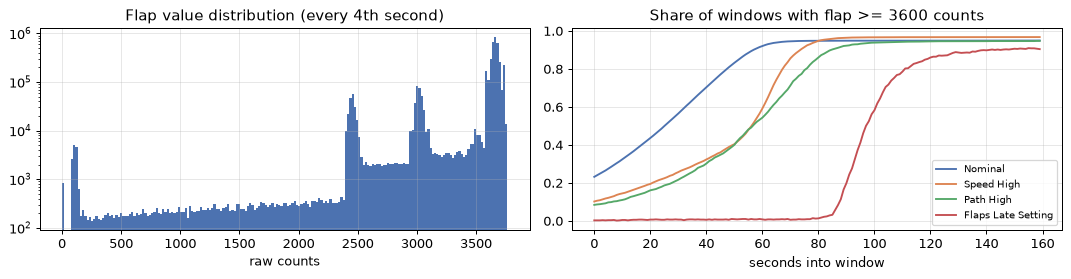

In [4]:
f = col("flap")
u, c = np.unique(f, return_counts=True)
print("distinct values:", len(u), "| range:", f.min(), "-", f.max())
step = np.abs(np.diff(f, axis=1))
print("non-zero 1-s step quantiles (50/90/99%):", np.quantile(step[step > 0], [.5, .9, .99]).round(1))
jump = (step > FLAP_JUMP_COUNTS).any(1)
print(f"windows with a >{FLAP_JUMP_COUNTS:.0f}-count jump:", int(jump.sum()),
      "| windows touching 0:", int((f == 0).any(1).sum()))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].hist(f[:, ::4].ravel(), bins=200, color="#4c72b0"); axes[0].set_yscale("log")
axes[0].set_title("Flap value distribution (every 4th second)"); axes[0].set_xlabel("raw counts")
for k in LABELS:
    idx = np.where(y == k)[0]
    axes[1].plot((f[idx] >= 3600).mean(0), color=CLASS_COLORS[k], label=LABELS[k])
axes[1].set_title("Share of windows with flap >= 3600 counts"); axes[1].set_xlabel("seconds into window")
axes[1].legend(fontsize=8); fig.tight_layout(); fig.savefig(FIG_DIR / "02_flap.png")

**Finding:** the values are not degrees and are not a small set of detents. They behave like a raw
synchro/position count that steps in increments of about 110–125 as the flaps travel, and settles at
about 3,650–3,700 at the final landing setting. A few windows have single-sample jumps to or from 0,
which are glitches.

**Decision:** treat flap as a continuous position signal with an unknown unit. Derive *time to reach the
final setting* (first second ≥ 3,600) as a candidate feature for the Flaps Late class. Flag windows with
jumps above 1,000 counts.

## 3. Aileron positions (idx 0, 1): not centred on 0

LH quantiles 0.1/1/50/99/99.9%: [ 41.9   42.78  84.53 105.91 124.  ] | share at floor 41.9: 0.00586


RH quantiles 0.1/1/50/99/99.9%: [ 41.9   49.59  82.63  93.21 119.23] | share at floor 41.9: 0.00527
corr(LH, RH): 0.183


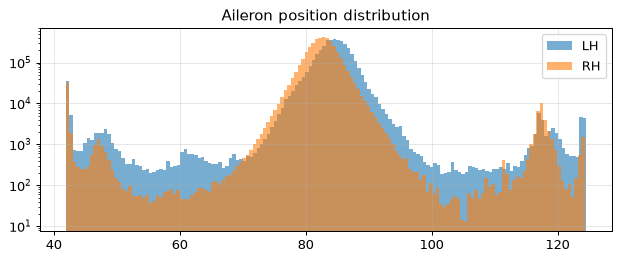

In [5]:
a_l, a_r = col("aileron_lh"), col("aileron_rh")
for name, a in (("LH", a_l), ("RH", a_r)):
    print(name, "quantiles 0.1/1/50/99/99.9%:", np.quantile(a, [.001, .01, .5, .99, .999]).round(2),
          "| share at floor 41.9:", round(float((a <= 41.9001).mean()), 5))
print("corr(LH, RH):", round(float(np.corrcoef(a_l[:, ::8].ravel(), a_r[:, ::8].ravel())[0, 1]), 3))
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(a_l[:, ::4].ravel(), bins=150, alpha=.6, label="LH"); ax.hist(a_r[:, ::4].ravel(), bins=150, alpha=.6, label="RH")
ax.set_yscale("log"); ax.legend(); ax.set_title("Aileron position distribution"); fig.tight_layout()
fig.savefig(FIG_DIR / "02_aileron.png")

**Finding:** both signals sit around 83–85 with a hard floor at 41.9. The left and right ailerons are
only weakly correlated (≈0.18), whereas ailerons normally deflect in opposite directions. The documented
unit "degree" does not match the data.

**Decision:** do not interpret these as deflection angles. Use them only after standardisation, and
treat their contribution to any explanation as low-confidence. This is an open question for the dataset
owner.

## 4. True heading (idx 17): values beyond ±180°

windows with |heading| > 180: 12204 (12.2%) | windows with a 1-s jump > 180 deg: 10452


after wrapping, |heading| > 180: 0 | 1-s jumps > 180 (wrapped, shortest arc): 0


median |true heading - selected heading| (wrapped): 5.38 deg


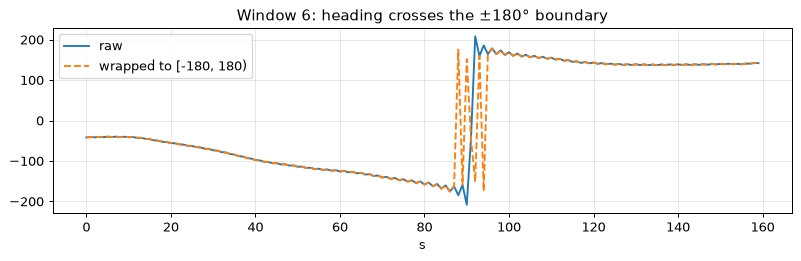

In [6]:
h = col("true_heading")
oor = (np.abs(h) > 180).any(1)
jumps = (np.abs(np.diff(h, axis=1)) > 180).any(1)
print("windows with |heading| > 180:", int(oor.sum()), f"({oor.mean():.1%})",
      "| windows with a 1-s jump > 180 deg:", int(jumps.sum()))
hw = wrap_degrees(h)
print("after wrapping, |heading| > 180:", int((np.abs(hw) > 180).sum()),
      "| 1-s jumps > 180 (wrapped, shortest arc):", int((np.abs(wrap_degrees(np.diff(hw, axis=1))) > 180).sum()))
print("median |true heading - selected heading| (wrapped):",
      round(float(np.median(np.abs(wrap_degrees(hw - col("selected_heading"))))), 2), "deg")

i = int(np.where(oor)[0][0])
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(h[i], label="raw"); ax.plot(hw[i], label="wrapped to [-180, 180)", ls="--")
ax.set_title(f"Window {i}: heading crosses the ±180° boundary"); ax.set_xlabel("s"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "02_heading.png")

**Finding:** heading is in degrees (it tracks the selected heading within a few degrees), but values
that cross ±180° were not wrapped consistently, which leaves values out to ±290 and false 1-second jumps.

**Decision:** wrap to [-180, 180) and then encode as sin/cos. Do the same for `selected_course` and
`selected_heading`. Never difference raw heading values.

## 5. Total pressure (idx 13): physically impossible values

In [7]:
p = col("total_pressure")
bad_win = np.median(p, axis=1) < PRESSURE_INVALID_MBAR
print(f"windows with median total pressure < {PRESSURE_INVALID_MBAR:.0f} mbar:", int(bad_win.sum()),
      "| labels:", {LABELS[k]: int(v) for k, v in zip(*np.unique(y[bad_win], return_counts=True))})
print("share of each such window below threshold:", np.unique((p[bad_win] < PRESSURE_INVALID_MBAR).mean(1)))
print("their median pressure range:", np.median(p[bad_win], axis=1).min().round(1), "-", np.median(p[bad_win], axis=1).max().round(1))
display(meta.loc[bad_win, ["aircraft_id", "record_time", "arrival_airport"]].value_counts("aircraft_id").head())

windows with median total pressure < 500 mbar: 39 | labels: {'Nominal': 32, 'Speed High': 3, 'Path High': 3, 'Flaps Late Setting': 1}
share of each such window below threshold: [1.]
their median pressure range: 26.4 - 106.7


aircraft_id
684    39
Name: count, dtype: int64

**Finding:** 39 windows report about 26–107 mbar for all 160 seconds, and **all of them come from
one aircraft (684)**. This is a sensor or recording fault on that aircraft, not a spike. Every other
window is in a plausible range.

**Decision:** flag these windows (`pressure_invalid`). Exclude them from training the nominal reference
model, and either keep them in evaluation with the flag recorded or impute total pressure. Document
whichever option is chosen.

## 6. Vertical acceleration (idx 18): spikes

samples outside [-1.0, 2.5] g: 15371 (0.096% of samples) | windows affected: 10663 (10.7%)
spike-window rate by class: {'Nominal': 0.107, 'Speed High': 0.111, 'Path High': 0.088, 'Flaps Late Setting': 0.133}
max consecutive spike length: 2


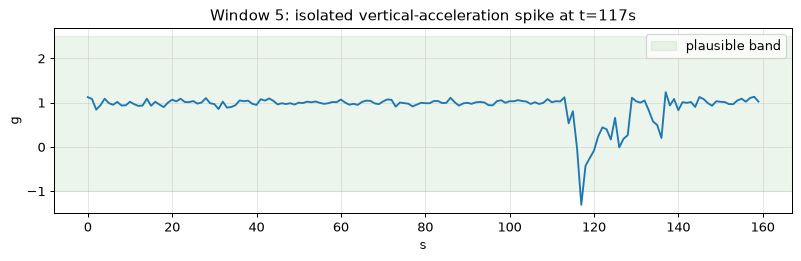

In [8]:
va = col("vert_accel")
lo, hi = VERT_ACCEL_RANGE_G
spk = (va < lo) | (va > hi)
win = spk.any(1)
print(f"samples outside [{lo}, {hi}] g:", int(spk.sum()), f"({spk.mean():.3%} of samples)",
      "| windows affected:", int(win.sum()), f"({win.mean():.1%})")
print("spike-window rate by class:", {LABELS[k]: round(float(win[y == k].mean()), 3) for k in LABELS})
print("max consecutive spike length:", max(int(np.max(np.diff(np.flatnonzero(np.r_[0, s, 0] == 0)) - 1)) for s in spk[win][:2000].astype(int)))
i = int(np.where(win)[0][0]); j = int(np.where(spk[i])[0][0])
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(va[i]); ax.axhspan(lo, hi, color="g", alpha=.08, label="plausible band")
ax.set_title(f"Window {i}: isolated vertical-acceleration spike at t={j}s"); ax.set_xlabel("s"); ax.set_ylabel("g"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "02_vert_accel.png")

**Finding:** the spikes are short (one or a few samples) and occur at a similar rate in every class.
They look like sensor noise, possibly aliasing from sampling at 1 Hz, rather than a sign of anomalies.

**Decision:** prefer robust window statistics (median, IQR, quantiles) for this variable over min/max.
Optionally apply a 3-sample median filter during preprocessing, and evaluate with and without it.

## 7. Altitude (idx 3): barometric, relative to sea level

In [9]:
alt = col("altitude")
print("altitude at window end, 1/50/99%:", np.quantile(alt[:, -1], [.01, .5, .99]).round(0))
end_by_ap = pd.Series(alt[:, -1]).groupby(meta["arrival_airport"].values).median().sort_values()
display(end_by_ap.tail(6).round(0).rename("median altitude at window end (ft)").to_frame())

altitude at window end, 1/50/99%: [ -10.  767. 3163.]


,median altitude at window end (ft)
KSLC,4199.0
KPVU,4481.0
KIDA,4724.0
KGJT,4820.0
KDEN,5342.0
KASE,7675.0


**Finding:** the highest altitudes come from high-elevation airports (for example KASE Aspen, about
7,800 ft; KDEN, about 5,400 ft), so the wide range is explained by barometric altitude above sea level,
not by errors.

**Decision:** for modelling, use altitude relative to the window's end, or height above the arrival
airport's elevation, instead of raw MSL altitude, so airport elevation does not dominate.

## 8. Per-window quality flags

In [10]:
flags = window_quality_flags(X)
flags.insert(0, "duplicate", duplicate_mask(X))
flags.insert(0, "label", y)
flags.insert(0, "flight_record", meta["flight_record"].values)
flags.insert(0, "data_instance", meta["data_instance"].values)

out = project_root() / "artifacts" / "reports" / "data_quality_flags.csv"
flags.to_csv(out, index=False)
print("written:", out)
summary = pd.DataFrame({
    "windows flagged": [int(flags.duplicate.sum()), int(flags.pressure_invalid.sum()), int(flags.flap_jump.sum()),
                         int(flags.heading_out_of_range.sum()), int((flags.vert_accel_spikes > 0).sum())],
}, index=["duplicate (2nd copy)", "pressure_invalid", "flap_jump", "heading_out_of_range", "vert_accel_spikes > 0"])
summary["share_%"] = (summary["windows flagged"] / len(flags) * 100).round(2)
display(summary)

written: C:\Users\shash\FlightOps-AI\artifacts\reports\data_quality_flags.csv


,windows flagged,share_%
duplicate (2nd copy),97,0.10
pressure_invalid,39,0.04
flap_jump,43,0.04
heading_out_of_range,12204,12.22
vert_accel_spikes > 0,10663,10.68


## Summary of decisions for Phase 2

| Issue | Finding | Preprocessing decision |
|-------|---------|------------------------|
| Duplicate windows | 97 pairs; same flight stored twice with a 2009 date | Drop the second copy before splitting |
| Flap position | Raw position count, not degrees or detents | Continuous; derive time to reach final setting; flag jumps |
| Aileron LH/RH | Not centred on 0, floor at 41.9, LH/RH weakly correlated | Standardise only; low confidence for explanations |
| True heading | Inconsistent wrapping past ±180° | Wrap to [-180, 180), then sin/cos (also course and selected heading) |
| Total pressure | 39 windows, all from aircraft 684, 26–107 mbar throughout | Flag; exclude from nominal training set |
| Vertical acceleration | Short spikes at a similar rate in all classes | Robust statistics; optional median filter |
| Altitude | Barometric MSL; high values are high-elevation airports | Use altitude relative to window end or airport |
| Selected course/heading | Constant in most windows | Low within-window information |
| Grouping | 35 aircraft; aircraft 657 holds ~32% of Speed High labels | Stratified split **and** aircraft-held-out evaluation |